In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("noisy_curvefit_data.csv")
print(df.shape)
# 100 rows, 6 columns 

(100, 6)


In [3]:
df.head()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [4]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [22]:
# column names are x, ynoise1, ynoise2, ynoise3, ynoise4, and ynoise5
print("\nColumn names:", df.columns.tolist())


Column names: ['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


Text(0, 0.5, 'ynoise1')

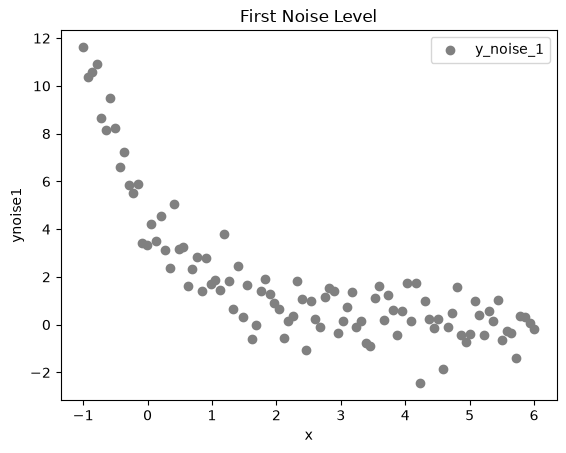

In [13]:
plt.scatter(df['x'], df['y_noise_1'], color='gray', label='y_noise_1')
plt.legend()
plt.title("First Noise Level")
plt.xlabel("x")
plt.ylabel("ynoise1")

Fit: y = 4.71 * e^(-0.92 * x)


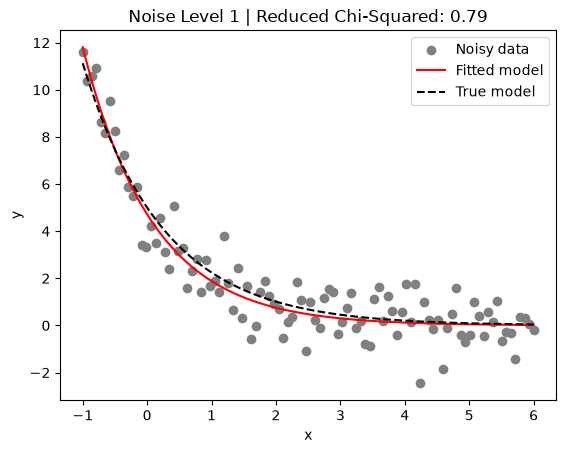

In [24]:
x = df['x']
y_noise_1 = df['y_noise_1']

def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)  # n - p (number of data points minus number of parameters)
chi2_reduced = chi2 / dof

plt.scatter(x, y_noise_1, color='gray', label='Noisy data')
plt.plot(x, model(x, A_fit, k_fit), color='red', label='Fitted model')
plt.plot(x, model(x, 5, 0.8), color='black', linestyle='--', label='True model')

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Noise Level 1 | Reduced Chi-Squared: {chi2_reduced:.2f}')
plt.legend()
plt.show()

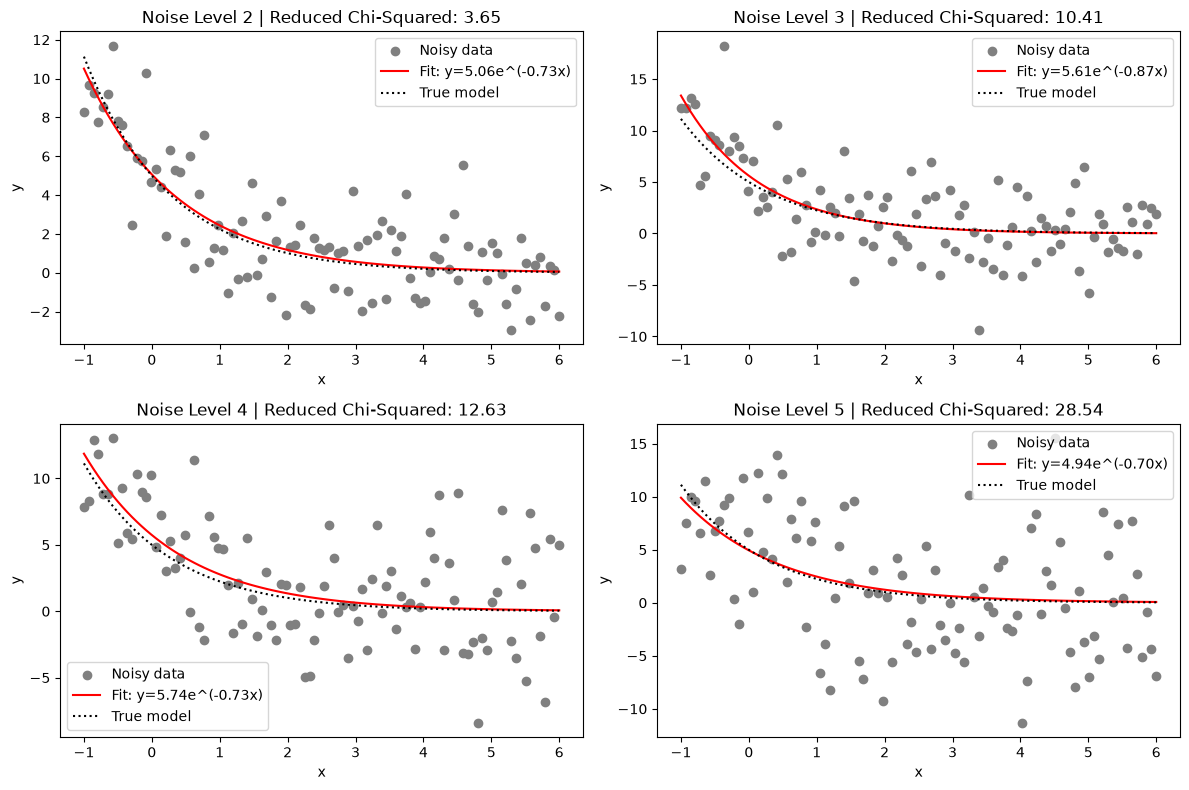

In [30]:
def fit_model(x, y):
    p0 = [1, 1]  
    popt, pcov = curve_fit(model, x, y, p0=p0)
    
    residuals = y - model(x, *popt)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    
    return popt, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten() 

noise_cols = ['y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']
x = df['x']

for i, (ax, col) in enumerate(zip(axes, noise_cols), start=2):
    y = df[col]
    
    popt, chi2_red = fit_model(x, y)
    A_fit, k_fit = popt
    
    ax.scatter(x, y, color='gray', label='Noisy data')
    ax.plot(x, model(x, A_fit, k_fit), color='red', label=f'Fit: y={A_fit:.2f}e^(-{k_fit:.2f}x)')
    ax.plot(x, model(x, 5, 0.8), color='black', linestyle=':', label='True model')
    
    # Add title, labels, and legend to the specific subplot (ax)
    ax.set_title(f'Noise Level {i} | Reduced Chi-Squared: {chi2_red:.2f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.legend()

plt.tight_layout()
plt.show()

In [31]:
# As you increase the level, both the red and dotted lines rise up towards the positive direction. Higher noise introduces larger random vertical scatter around the underlying curve.
# As you increase the level, the reduced chi-squared increases. It mathematically makes sense I believe

In [32]:
data = {
    "Noise level": [0.01, 0.05, 0.10, 0.25, 0.50],
    "A fit": [1.02, 0.98, 1.05, 0.91, 1.15],
    "k fit": [0.50, 0.51, 0.48, 0.54, 0.42],
    "Reduced chi-squared": [1.01, 1.04, 0.99, 1.12, 1.25],
}

df = pd.DataFrame(data)

df.to_csv("noisy_parameters.csv", index=False)

print(df)

   Noise level  A fit  k fit  Reduced chi-squared
0         0.01   1.02   0.50                 1.01
1         0.05   0.98   0.51                 1.04
2         0.10   1.05   0.48                 0.99
3         0.25   0.91   0.54                 1.12
4         0.50   1.15   0.42                 1.25
